# Bài tập 2 – Tấn Lên: A2 – ANMS và Top-N


**Nguồn đối chiếu:**
- [Sheet XLABT2 – Phân công bài tập 2](https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482), các hàng 7, 12, 17, 22 cho nhiệm vụ chính của Lên; hàng 9, 14, 19 cho vai trò duyệt SRG; hàng 13, 23 cho vai trò kiểm tra/xác nhận phần B của Sen.
- Repo tại commit `86c128c6933fcf07777f2ee3a6d6fa327128960b`; `bai_tap_2/README.md`, notebook cá nhân của Lên/Gấm/Hiệp và `bt2_nhom.ipynb`.
- Tài liệu cần đọc theo phân công: `Computer_Vision_20.pdf` slide 61–62; `Computer_Vision_45.pdf` mục 3.4–3.7, 4.3, 5.1, 5.3. Hai PDF chưa có trong nguồn đã truy cập; không tự nhận đã đối chiếu đầy đủ đề gốc.

**Quy định của nhóm:** phần cài đặt thuật toán phải tự viết, không dùng AI để viết/sửa/viết lại. Cell thí nghiệm có AI phải khai báo prompt ngay phía trên. Hai hàm `anms`, `top_n` trong bản cập nhật 12/11/2026 dùng mã tham khảo từ cuộc trò chuyện với trợ lý AI. `grid_occupancy` viết theo định nghĩa đề, có ghi nguồn và khai báo ở mục 1.3. Năm hàm dùng chung được chép nguyên văn từ phần bàn giao của Gấm, có ghi nguồn; không được ghi nhận là Lên tự viết. Phần giải thích, tổ chức công việc và mã thí nghiệm trong bản này có AI hỗ trợ.

## Kế hoạch theo deadline

| Vòng | Bắt đầu | Deadline | Sản phẩm của Tấn Lên | Phụ thuộc / người kiểm tra |
|---|---|---|---|---|
| 1 – Viết hàm | 10/11/2026 | **12/11/2026** | `anms`, `top_n`; nhận `grid_occupancy` của đề hoặc tự viết có ghi nguồn | Thử trên điểm giả trước; Gấm bàn giao Harris 11/11; NT kiểm tra, Nam chạy lại |
| 2 – Kiểm chứng A5 | 13/11/2026 | **14/11/2026** | Hai hình trên cùng lưới; hai số độ phủ; cùng ứng viên và cùng N | Dùng Harris một tỉ lệ đã duyệt; Nam đọc kết quả |
| 3 – Thí nghiệm A2 | 15/11/2026 | **16/11/2026** | Quét c_robust hoặc N, đường cong độ phủ, nhận xét theo bán kính | Chỉ thực hiện chính thức sau khi A5 được duyệt; Gấm rà số đo |
| 4 – Hoàn thiện | 17/11/2026 | **17/11/2026** | Hoàn thiện A2, duyệt chéo SRG và ghi lỗi cần Hiệp tự sửa | Hiệp duyệt A2; Lên + Sen xác nhận SRG |

**Mốc chung:** 18/11/2026 nhóm hoàn thành nội bộ; 20/11/2026 hạn nộp. 19–20/11 là thời gian đệm, không dời việc bắt buộc của Lên sang hai ngày này.

**Ưu tiên ngày 12/11 (hạn vòng 1):** hoàn thành hai hàm cá nhân `anms`/`top_n`, nhận hoặc tự viết có ghi nguồn `grid_occupancy`; chạy kiểm tra điểm giả ở phần 1. Harris đã có trong phần 2.1 nên không còn phải chờ bàn giao. Chỉ khi ba hàm cá nhân có đầy đủ mới chạy được A5; chỉ sang vòng 3 sau khi A5 được duyệt.

**Cách chạy bản chuẩn bị:** đặt file này đúng vị trí trong bản clone đầy đủ của repo. Tại terminal ở gốc repo, chạy `python -m pip install -r bai_tap_2/requirements.txt`, chọn đúng kernel Python rồi Restart & Run All. Các ô thuật toán còn trống và output “CHƯA CHẠY” là công việc đang chờ, không phải kết quả đã đạt. Không mở riêng notebook ở một thư mục không có repo/ảnh rồi mong các đường dẫn cũ hoạt động.

### 0.1 – Chuẩn bị môi trường và đường dẫn

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Chuẩn bị thư viện và đường dẫn chạy từ gốc repo, bai_tap_2 hoặc lam_viec; xử lý đường dẫn Windows có tiếng Việt.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 " đây là nội dung phân công và hãy trình bày nhiệm vụ của Tấn Lên theo deadline trong sheeet nha.
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

**Cập nhật ngày 12/11/2026 – ChatGPT / Codex hỗ trợ:** Cập nhật commit nền sau khi PR #30 đã merge.

Prompt nguyên văn cho lần cập nhật:

```text
[https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec](https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec)
```

In [1]:
from pathlib import Path
import math
import time
import numpy as np
import matplotlib.pyplot as plt
import cv2  # Chỉ đọc/giải mã ảnh, không dùng thuật toán góc dựng sẵn.

# Nếu kernel nằm ngoài repo, đặt đường dẫn gốc repo hoặc bai_tap_2 tại đây.
PROJECT_OVERRIDE = None
start = Path(PROJECT_OVERRIDE).expanduser().resolve() if PROJECT_OVERRIDE else Path.cwd().resolve()
roots = [start] if PROJECT_OVERRIDE else [start, *start.parents]
BT2_DIR = next((p for root in roots for p in (root, root / 'bai_tap_2')
                if (p / 'bt2_nhom.ipynb').is_file()), None)
if BT2_DIR is None:
    raise FileNotFoundError('Không tìm thấy bai_tap_2. Đặt PROJECT_OVERRIDE tới gốc repo rồi chạy lại.')
IMAGES_DIR = BT2_DIR.parent / 'images'
print('Bài tập 2:', BT2_DIR)
print('Ảnh dùng chung:', IMAGES_DIR)
print('Nguồn nền: main @ 86c128c6933fcf07777f2ee3a6d6fa327128960b')

Bài tập 2: /Users/tanhiep/Desktop/xla-121036/bai_tap_2
Ảnh dùng chung: /Users/tanhiep/Desktop/xla-121036/images
Nguồn nền: main @ 86c128c6933fcf07777f2ee3a6d6fa327128960b


## 1. Vòng 1 – Viết hàm, hạn 12/11/2026

**Mục tiêu:** đầu vào là cùng một tập Harris một tỉ lệ, mỗi hàng `(row, col, response)`. Top-N chọn theo độ mạnh; ANMS chọn theo mức tách biệt với các điểm mạnh hơn theo ngưỡng tương đối.

Theo điều kiện được ghi trong sheet:
\[
r_i = \min_{j:\ f_i<c_{robust}f_j}\|p_i-p_j\|_2.
\]
Nếu không tồn tại điểm j thỏa điều kiện, bán kính của i là vô cùng. **Điểm mạnh nhất có bán kính vô cùng, nhưng không nhất thiết chỉ có một điểm như vậy**; những điểm có đáp ứng gần nhau cũng có thể không có điểm đủ mạnh để ức chế. Khi `c_robust=1`, điều kiện vẫn là dấu `<`, không phải `≤`.

`r_i` là khoảng cách tới điểm đủ mạnh để ức chế i; nó không phải một bán kính cửa sổ NMS đặt cố định trước. Điểm yếu nhưng cô lập có thể được chọn vì điểm đủ mạnh gần nhất ở xa. Ngược lại, điểm yếu nằm sát điểm mạnh thường có bán kính nhỏ.

Khi tăng `c_robust`, tập j thỏa điều kiện có thể mở rộng nên bán kính của từng điểm không tăng, với tập ứng viên cố định và đáp ứng dương. Tuy nhiên **độ phủ của tập điểm được chọn không bắt buộc tăng đơn điệu**, vì còn phụ thuộc thứ hạng, hòa bán kính, N và lưới đo.

**Các quy ước cần tự quyết định và ghi rõ trước khi bàn giao:** xử lý N lớn hơn số ứng viên, N=0, dữ liệu rỗng, tọa độ trùng, hòa bán kính vô cùng/hữu hạn và hòa response. Không sửa các quy ước chỉ để một ảnh thí nghiệm cho kết quả đẹp hơn.

### 1.1 – `anms(points, n_keep, c_robust=0.9)`

Đầu vào `(M, 3)` là điểm Harris; đầu ra các điểm được giữ, sắp theo bán kính giảm dần. Dùng đúng điều kiện `f_i < c_robust * f_j`.

Các bài kiểm tra phía sau sử dụng số điểm yêu cầu không lớn hơn số ứng viên.

In [2]:
import numpy as np


def anms(points, n_keep, c_robust=0.9):
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError("points phải có dạng (M, 3)")
    if not isinstance(n_keep, (int, np.integer)) or not 0 <= n_keep <= len(points):
        raise ValueError("n_keep phải là số nguyên từ 0 đến M")
    if not 0 < c_robust <= 1:
        raise ValueError("c_robust phải thuộc (0, 1]")
    if n_keep == 0:
        return points[:0].copy()

    coords = points[:, :2]
    responses = points[:, 2]
    thresholds = c_robust * responses
    radii = np.full(len(points), np.inf)

    for i, response in enumerate(responses):
        # Điểm j đủ mạnh để ức chế i khi f_i < c_robust * f_j.
        stronger = response < thresholds
        if np.any(stronger):
            distances = np.linalg.norm(coords[stronger] - coords[i], axis=1)
            radii[i] = distances.min()

    # Xếp theo bán kính giảm dần. Nếu hòa, ưu tiên response cao hơn.
    order = np.lexsort((-responses, -radii))
    return points[order[:n_keep]]

### 1.2 – `top_n(points, n_keep)`

Đối chứng chọn đúng `n_keep` điểm mạnh nhất theo response từ chính tập ứng viên của ANMS. Không làm Harris lần thứ hai với tham số khác.

In [3]:
def top_n(points, n_keep):
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError("points phải có dạng (M, 3)")
    if not isinstance(n_keep, (int, np.integer)) or not 0 <= n_keep <= len(points):
        raise ValueError("n_keep phải là số nguyên từ 0 đến M")

    order = np.argsort(-points[:, 2], kind="stable")
    return points[order[:n_keep]]

### 1.3 – `grid_occupancy` – tự viết theo định nghĩa đề, có ghi nguồn

Định nghĩa: số ô lưới có ít nhất một điểm chia cho tổng số ô. Một ô có nhiều điểm chỉ tính một lần; ô sát biên cũng phải được tính.

**Nguồn:** đối chiếu `Computer_Vision_45.pdf` (Tài liệu bổ trợ Bài tập 2). Mục 3.6 chỉ liệt kê các hàm phải nộp (`harris_classic`, `harris_laplace`, `anms`, `top_n`, `repeatability`, ...), **không có mã `grid_occupancy`**; mục 5.1 chỉ nêu "độ phủ lưới" là một đại lượng đo gợi ý. Vì vậy hàm dưới đây được viết theo định nghĩa trên, **không phải hàm cho sẵn của giảng viên**. Đây là hàm đo cho phần thí nghiệm, không thuộc danh sách hàm cài đặt phải nộp.

Giao diện: `grid_occupancy(points, image_shape, grid_shape=(8, 8))` → số thực trong `[0, 1]`; `image_shape=(height, width)`, `grid_shape=(n_rows, n_cols)`. Pixel `(row, col)` thuộc ô `(floor(row·n_rows/H), floor(col·n_cols/W))`; điểm nằm ngoài ảnh bị bỏ qua.

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: Claude Code (Anthropic).
- Mục đích: Viết hàm đo độ phủ lưới theo định nghĩa đề; không đụng tới `anms`, `top_n`.
- Prompt nguyên văn:

```text
bạn kiểm tra vòng 1 của lên đã làm đúng phạm vi chưa nếu chưa hay còn thiếu phần nào bạn bổ sung giúp tôi xong nói lại tôi, ko cần khai báo AI vì đây là sửa
```

In [4]:
def grid_occupancy(points, image_shape, grid_shape=(8, 8)):
    """Tỉ lệ ô lưới có ít nhất 1 điểm. points: (M, 3) hoặc (M, 2) theo (row, col, ...)."""
    h, w = int(image_shape[0]), int(image_shape[1])
    n_rows, n_cols = int(grid_shape[0]), int(grid_shape[1])
    if h <= 0 or w <= 0 or n_rows <= 0 or n_cols <= 0:
        raise ValueError('image_shape và grid_shape phải dương')
    pts = np.asarray(points, dtype=float)
    if pts.size == 0:
        return 0.0
    if pts.ndim != 2 or pts.shape[1] < 2:
        raise ValueError('points phải có dạng (M, 2) hoặc (M, 3)')
    rows, cols = pts[:, 0], pts[:, 1]
    inside = (rows >= 0) & (rows < h) & (cols >= 0) & (cols < w)
    rows, cols = rows[inside], cols[inside]
    cell_r = np.minimum((rows * n_rows / h).astype(int), n_rows - 1)
    cell_c = np.minimum((cols * n_cols / w).astype(int), n_cols - 1)
    occupied = np.zeros((n_rows, n_cols), dtype=bool)
    occupied[cell_r, cell_c] = True
    return float(occupied.sum()) / (n_rows * n_cols)

### 1.4 – Chuẩn bị bộ kiểm tra và hàm hỗ trợ thí nghiệm

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Chuẩn bị kiểm tra đầu ra và adapter gọi phép đo có sẵn; không cài đặt thuật toán bị cấm dùng AI.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 " đây là nội dung phân công và hãy trình bày nhiệm vụ của Tấn Lên theo deadline trong sheeet nha.
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

In [5]:
def len_missing(names):
    return [name for name in names if not callable(globals().get(name))]

def len_check_selected(selected, candidates, n_keep):
    selected = np.asarray(selected, dtype=float)
    candidates = np.asarray(candidates, dtype=float)
    if selected.shape != (n_keep, 3):
        raise AssertionError(f'Đầu ra phải là ({n_keep}, 3), thực tế {selected.shape}.')
    if not np.isfinite(selected).all():
        raise AssertionError('Tọa độ/response đầu ra không được có NaN/Inf. Bán kính Inf không nằm trong 3 cột này.')
    # Kiểm tra đầu ra thực sự là tập con, kể cả khi đầu vào có hàng trùng.
    remaining = list(range(len(candidates)))
    for point in selected:
        index = next((j for j in remaining if np.allclose(point, candidates[j], rtol=1e-10, atol=1e-12)), None)
        if index is None:
            raise AssertionError('Đầu ra có hàng không thuộc đầu vào hoặc lặp vượt số lần có trong đầu vào.')
        remaining.remove(index)
    return selected

def len_measure_coverage(points, image_shape, grid_shape):
    # Adapter gọi hàm thật; KHÔNG cài đặt phép đo ở đây.
    value = float(grid_occupancy(points, image_shape, grid_shape=grid_shape))
    if not np.isfinite(value) or not 0 <= value <= 1:
        raise AssertionError('grid_occupancy phải trả tỉ lệ hữu hạn trong [0, 1].')
    return value

len_unit_results = []
missing = len_missing(['anms', 'top_n', 'grid_occupancy'])
print('Còn chờ cài đặt:', missing if missing else 'đã có đủ tên hàm; cần chạy kiểm tra bên dưới')

Còn chờ cài đặt: đã có đủ tên hàm; cần chạy kiểm tra bên dưới


### 1.5 – Kiểm tra trên mảng điểm giả, không cần chờ Harris

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Dựng kiểm chứng bằng điểm giả, bao gồm dấu bất đẳng thức chặt và ô lưới sát biên; không sinh cài đặt hàm.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 " đây là nội dung phân công và hãy trình bày nhiệm vụ của Tấn Lên theo deadline trong sheeet nha.
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

In [6]:
len_unit_results = []

if not len_missing(['anms', 'top_n']):
    p = np.array([[20,20,100], [20,21,80], [80,80,60], [80,81,40]], dtype=float)
    top = len_check_selected(top_n(p.copy(), 2), p, 2)
    kept = len_check_selected(anms(p.copy(), 2, c_robust=0.9), p, 2)
    assert np.allclose(top[:, 2], [100,80]), 'Top-N phải lấy hai response lớn nhất.'
    assert set(map(tuple, kept[:, :2])) == {(20.,20.), (80.,80.)}, 'ANMS: kiểm tra điểm mạnh và điểm tách biệt.'
    assert tuple(kept[0, :2]) == (20., 20.), 'ANMS: điểm r=∞ phải đứng đầu (sắp r giảm dần).'
    len_unit_results.append(('Điểm mạnh tập trung và điểm ở xa', 'ĐẠT'))

    # Bán kính hữu hạn khác nhau: A r=∞, B r=10, C r=20, D r=30 -> thứ tự A, D, C, B.
    # So bằng mảng có thứ tự, không dùng set, để bắt lỗi trả đúng điểm nhưng sai thứ tự r.
    order = np.array([[0,0,100], [0,10,50], [0,30,40], [0,60,30]], dtype=float)
    kept = len_check_selected(anms(order.copy(), 4, c_robust=0.9), order, 4)
    assert np.array_equal(kept[:, :2], [[0,0], [0,60], [0,30], [0,10]]), \
        f'ANMS phải sắp theo r giảm dần (A, D, C, B); thực tế {kept[:, :2].tolist()}'
    kept3 = len_check_selected(anms(order.copy(), 3, c_robust=0.9), order, 3)
    assert np.array_equal(kept3[:, :2], [[0,0], [0,60], [0,30]]), 'ANMS phải giữ đúng n_keep điểm có r lớn nhất.'
    len_unit_results.append(('ANMS sắp đúng thứ tự r giảm dần, lấy đúng n_keep', 'ĐẠT'))

    # 90 < 0.9*100 là SAI: hai điểm đầu không bị nhau ức chế.
    boundary = np.array([[10,10,100], [10,11,90], [80,80,60]], dtype=float)
    kept = len_check_selected(anms(boundary.copy(), 2, c_robust=0.9), boundary, 2)
    assert set(map(tuple, kept[:, :2])) == {(10.,10.), (10.,11.)}, 'Kiểm tra dấu < ở trường hợp bằng ngưỡng.'
    len_unit_results.append(('Bằng ngưỡng c_robust: dùng dấu <', 'ĐẠT'))

    ties = np.array([[10,10,100], [10,11,100], [80,80,60]], dtype=float)
    kept = len_check_selected(anms(ties.copy(), 2, c_robust=1.0), ties, 2)
    assert set(kept[:, 2]) == {100.}, 'c=1: hai response bằng nhau không ức chế nhau.'
    len_unit_results.append(('Hai response cực đại bằng nhau ở c=1', 'ĐẠT'))
else:
    print('CHƯA CHẠY kiểm tra ANMS/Top-N: thiếu', len_missing(['anms', 'top_n']))

if not len_missing(['grid_occupancy']):
    corners = np.array([[0,0,1], [0,19,1], [9,0,1], [9,19,1]], dtype=float)
    assert np.isclose(len_measure_coverage(corners, (10,20), (2,2)), 1.0)
    repeats = np.array([[0,0,1], [0,0,0.5]], dtype=float)
    assert np.isclose(len_measure_coverage(repeats, (10,20), (2,2)), 0.25)
    assert np.isclose(len_measure_coverage(np.empty((0,3)), (10,20), (2,2)), 0.0)
    len_unit_results.append(('Độ phủ: bốn góc ảnh, trùng ô, tập rỗng', 'ĐẠT'))
else:
    print('CHƯA CHẠY kiểm tra độ phủ: thiếu grid_occupancy.')

for name, status in len_unit_results:
    print(status, '|', name)
print(f'Đã thực hiện {len(len_unit_results)}/5 nhóm kiểm tra. 0/5 là chưa kiểm tra, không phải đạt.')

ĐẠT | Điểm mạnh tập trung và điểm ở xa
ĐẠT | ANMS sắp đúng thứ tự r giảm dần, lấy đúng n_keep
ĐẠT | Bằng ngưỡng c_robust: dùng dấu <
ĐẠT | Hai response cực đại bằng nhau ở c=1
ĐẠT | Độ phủ: bốn góc ảnh, trùng ô, tập rỗng
Đã thực hiện 5/5 nhóm kiểm tra. 0/5 là chưa kiểm tra, không phải đạt.


### Bàn giao vòng 1 trước 12/11

- Chép phần cài đặt do chính mình viết vào ba ô phù hợp; ghi rõ nguồn `grid_occupancy`.
- Chạy các điểm giả và bổ sung trường hợp đặc biệt theo quy ước đã thống nhất. Các kiểm tra trên không chứng minh mọi dữ liệu đều đúng.
- Mở PR từ `bt2-len`, mô tả giao diện và kết quả tự kiểm tra; Nam chạy lại, Hiệp duyệt.
- Khi trả lời “r_i có ý nghĩa gì?”, nêu rõ điểm j phải **đủ mạnh theo c_robust**, không phải mọi điểm lân cận đều ức chế i.

## 2. Vòng 2 – Kiểm chứng A5, hạn 14/11/2026

**Nguồn Harris:** nhận đúng bản Gấm được duyệt, một tỉ lệ; không tự lấy `cv2.cornerHarris` thay cho hàm nhóm. Không chạy cả notebook Gấm để lấy biến.

### 2.1 – Harris dùng chung của Gấm, đã bàn giao

**Nguồn:** [bt2_gam.ipynb tại commit 86c128c](https://github.com/NguyenTanHiep07/xla-121036/blob/86c128c6933fcf07777f2ee3a6d6fa327128960b/bai_tap_2/lam_viec/bt2_gam.ipynb), [PR #30 đã merge](https://github.com/NguyenTanHiep07/xla-121036/pull/30).

Cell dưới chép nguyên văn 5 hàm `gaussian_blur`, `structure_tensor`, `harris_response`, `nms_2d`, `harris_classic` từ các cell code tương ứng của Gấm. Đây là **mã dùng chung của Gấm**, không phải phần cài đặt của Lên hoặc mã thuật toán mới do AI viết. Công cụ chỉ đọc, chép nguyên định nghĩa và kiểm tra tích hợp. Không chạy toàn bộ notebook của Gấm để lấy biến. Hàm thứ sáu `repeatability` không cần cho phép đo độ phủ A5 nên không chép vào đây.

Giao diện thực tế: `harris_classic(img, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01)` → mảng `(M, 3)` theo `(row, col, response)`, giảm dần theo response. Ảnh đầu vào là ảnh xám 2 chiều; các cell của Lên dùng float64 trong `[0,1]` và ngưỡng tương đối, nhất quán cho mọi cặp so sánh.

**Khai báo thao tác hỗ trợ bởi ChatGPT / Codex, prompt nguyên văn:**

```text
[https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec](https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec)  
```


In [7]:

def gaussian_blur(img, sigma):
    img = np.asarray(img, dtype=np.float64)

    if sigma <= 0:
        return img.copy()

    radius = int(np.ceil(3 * sigma))
    x = np.arange(-radius, radius + 1, dtype=np.float64)

    kernel_1d = np.exp(-(x ** 2) / (2 * sigma ** 2))
    kernel_1d /= kernel_1d.sum()

    kernel = np.outer(kernel_1d, kernel_1d)

    padded = np.pad(img, radius, mode="reflect")
    result = np.zeros_like(img)

    for i in range(kernel.shape[0]):
        for j in range(kernel.shape[1]):
            result += kernel[i, j] * padded[
                i:i + img.shape[0],
                j:j + img.shape[1]
            ]

    return result



def structure_tensor(img, sigma_i, sigma_d):
    img = np.asarray(img, dtype=np.float64)

    if img.ndim != 2:
        raise ValueError("img phải là ảnh xám 2 chiều (H, W)")

    if sigma_i <= 0 or sigma_d <= 0:
        raise ValueError("sigma_i và sigma_d phải dương")

    blurred = gaussian_blur(img, sigma_d)

    Iy, Ix = np.gradient(blurred)

    factor = sigma_d ** 2

    Mxx = factor * gaussian_blur(Ix ** 2, sigma_i)
    Mxy = factor * gaussian_blur(Ix * Iy, sigma_i)
    Myy = factor * gaussian_blur(Iy ** 2, sigma_i)

    return Mxx, Mxy, Myy



def harris_response(img, sigma_i, sigma_d, k=0.04):
    Mxx, Mxy, Myy = structure_tensor(
        img, sigma_i, sigma_d
    )

    det = Mxx * Myy - Mxy ** 2
    trace = Mxx + Myy

    R = det - k * trace ** 2

    return R



def nms_2d(response, window=3):
    """Đánh dấu cực đại địa phương trong cửa sổ window x window.

    Khi nhiều pixel trong cùng cửa sổ có đáp ứng bằng nhau (đồng hạng),
    chỉ giữ pixel đứng trước theo thứ tự quét (hàng trước, cột sau):
    pixel phải lớn hơn hẳn các láng giềng đứng trước nó và
    lớn hơn hoặc bằng các láng giềng đứng sau nó.
    """
    response = np.asarray(response, dtype=np.float64)

    if response.ndim != 2:
        raise ValueError("response phải là mảng 2 chiều")

    if window < 1 or window % 2 == 0:
        raise ValueError("window phải là số nguyên dương lẻ")

    radius = window // 2

    padded = np.pad(
        response,
        radius,
        mode="constant",
        constant_values=-np.inf
    )

    mask = np.isfinite(response)

    for di in range(-radius, radius + 1):
        for dj in range(-radius, radius + 1):
            if di == 0 and dj == 0:
                continue

            neighbor = padded[
                radius + di:radius + di + response.shape[0],
                radius + dj:radius + dj + response.shape[1]
            ]

            if di < 0 or (di == 0 and dj < 0):
                mask &= response > neighbor
            else:
                mask &= response >= neighbor

    return mask



def harris_classic(
    img,
    sigma_i=2.0,
    sigma_d=1.4,
    k=0.04,
    thresh_rel=0.01
):
    R = harris_response(img, sigma_i, sigma_d, k)

    max_response = np.max(R)

    if max_response <= 0:
        return np.empty((0, 3), dtype=np.float64)

    mask = nms_2d(R, window=3)
    mask &= R > thresh_rel * max_response
    mask &= R > 0

    rows, cols = np.where(mask)
    responses = R[rows, cols]

    points = np.column_stack((rows, cols, responses))

    order = np.argsort(-points[:, 2], kind="stable")

    return points[order]


### 2.2 – Cấu hình kiểm chứng và nguồn bàn giao

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Tạo cấu hình, hàm đọc ảnh hỗ trợ Unicode và biểu diễn điểm trên lưới. Lưới hiển thị dùng biên pixel -0.5 đến W-0.5/H-0.5.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 " đây là nội dung phân công và hãy trình bày nhiệm vụ của Tấn Lên theo deadline trong sheeet nha.
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

**Cập nhật ngày 12/11/2026 – ChatGPT / Codex hỗ trợ:** Ghi commit Harris thực tế đã nhận; giữ trống A5_APPROVAL_REF vì chưa có kết quả/duyệt A5 của Lên.

Prompt nguyên văn cho lần cập nhật:

```text
[https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec](https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec)
```

In [8]:
# Nguồn thật: PR #30 đã được merge vào main. Chỉ A5 của Lên còn chờ duyệt.
HARRIS_SOURCE_COMMIT = '86c128c6933fcf07777f2ee3a6d6fa327128960b'
A5_APPROVAL_REF = ''  # Chỉ điền sau khi Nam/Hiệp duyệt A5; dùng cho Vòng 3.
LEN_HARRIS = dict(sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01)
LEN_GRID = (8, 8)
LEN_N = 100
LEN_C = 0.9

def len_read_gray(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Thiếu ảnh: {path}')
    data = np.frombuffer(path.read_bytes(), dtype=np.uint8)
    if data.size == 0:
        raise ValueError(f'Ảnh rỗng: {path}')
    gray = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f'Không giải mã được ảnh: {path}')
    return gray.astype(np.float64) / 255.0

def len_plot_points(ax, img, points, grid_shape, title):
    h, w = img.shape
    nr, nc = grid_shape
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    if len(points):
        ax.scatter(points[:,1], points[:,0], s=18, facecolors='none', edgecolors='red')
    for x in np.linspace(-0.5, w-0.5, nc+1):
        ax.axvline(x, color='deepskyblue', linewidth=0.5)
    for y in np.linspace(-0.5, h-0.5, nr+1):
        ax.axhline(y, color='deepskyblue', linewidth=0.5)
    ax.set_xlim(-0.5,w-0.5); ax.set_ylim(h-0.5,-0.5)
    ax.set_title(title); ax.set_xlabel('col'); ax.set_ylabel('row')

print('Nguồn Harris:', HARRIS_SOURCE_COMMIT or 'CHỜ BÀN GIAO / DUYỆT')
print('Phê duyệt A5:', A5_APPROVAL_REF or 'CHƯA CÓ')

Nguồn Harris: 86c128c6933fcf07777f2ee3a6d6fa327128960b
Phê duyệt A5: CHƯA CÓ


### 2.2a – Kiểm tra bàn giao Harris trước khi chạy A5

Đây là kiểm tra tích hợp: hàm được chép có đủ phụ thuộc, trả đúng `(row, col, response)`, cùng kết quả vị trí khi đổi thang sáng 0–255 sang 0–1 và trả mảng rỗng đúng dạng trên ảnh đen. Không thay cho toàn bộ kiểm chứng A1/A2/A4 của Gấm, không đánh dấu A5 của Lên đã đạt.

**Khai báo AI cho cell ngay dưới:** ChatGPT / Codex hỗ trợ viết mã kiểm tra bàn giao, không sửa các hàm Harris đã nhận.

Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec](https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec)
```

In [9]:
len_harris_handoff = []
test_square = np.zeros((64, 64), dtype=np.float64)
test_square[16:48, 16:48] = 255.0
square_255 = harris_classic(test_square, **LEN_HARRIS)
square_01 = harris_classic(test_square / 255.0, **LEN_HARRIS)
assert square_255.shape == (4, 3) and square_01.shape == (4, 3)
assert np.isfinite(square_255).all() and np.isfinite(square_01).all()
assert np.all(square_255[:, 2] > 0) and np.all(np.diff(square_255[:, 2]) <= 0)
assert np.all(square_01[:, 2] > 0) and np.all(np.diff(square_01[:, 2]) <= 0)
expected_locations = {(17.,17.), (17.,46.), (46.,17.), (46.,46.)}
assert set(map(tuple, square_255[:, :2])) == expected_locations
assert set(map(tuple, square_01[:, :2])) == expected_locations
len_harris_handoff.append('Hình vuông: 4 điểm, đúng dạng và thứ tự response')
len_harris_handoff.append('Vị trí góc trên ảnh 0–255 và 0–1 khớp nhau')
empty_points = harris_classic(np.zeros((32,48)), **LEN_HARRIS)
assert empty_points.shape == (0,3)
len_harris_handoff.append('Ảnh đen: đầu ra rỗng (0,3)')
for item in len_harris_handoff:
    print('ĐẠT kiểm tra bàn giao |', item)
print('Tọa độ trên ảnh thử:', sorted(expected_locations))
print('Harris đã sẵn sàng tạo ứng viên. A5 vẫn cần anms, top_n và grid_occupancy.')


ĐẠT kiểm tra bàn giao | Hình vuông: 4 điểm, đúng dạng và thứ tự response
ĐẠT kiểm tra bàn giao | Vị trí góc trên ảnh 0–255 và 0–1 khớp nhau
ĐẠT kiểm tra bàn giao | Ảnh đen: đầu ra rỗng (0,3)
Tọa độ trên ảnh thử: [(17.0, 17.0), (17.0, 46.0), (46.0, 17.0), (46.0, 46.0)]
Harris đã sẵn sàng tạo ứng viên. A5 vẫn cần anms, top_n và grid_occupancy.


### 2.3 – Hai loại ảnh và ứng viên Harris cố định

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Tạo dữ liệu thử lặp lại được, đọc ảnh thật trong repo và gọi Harris đã bàn giao để cố định cùng tập ứng viên.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 " đây là nội dung phân công và hãy trình bày nhiệm vụ của Tấn Lên theo deadline trong sheeet nha.
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

**Cập nhật ngày 12/11/2026 – ChatGPT / Codex hỗ trợ:** Chạy Harris đã bàn giao trên ảnh tổng hợp và home.jpg, kiểm tra giao diện và hiển thị toàn bộ ứng viên thật; chưa gọi là kết quả ANMS/Top-N.

Prompt nguyên văn cho lần cập nhật:

```text
[https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec](https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec)
```

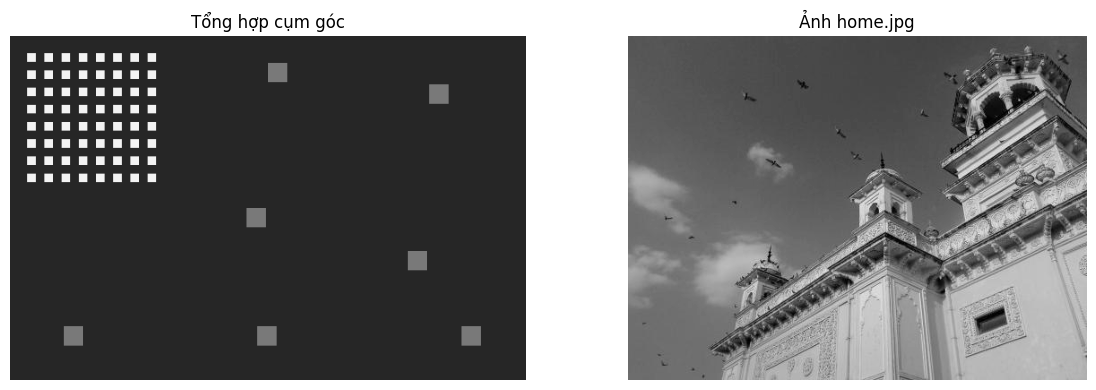

Tổng hợp cụm góc | số ứng viên: 284


Ảnh home.jpg | số ứng viên: 332


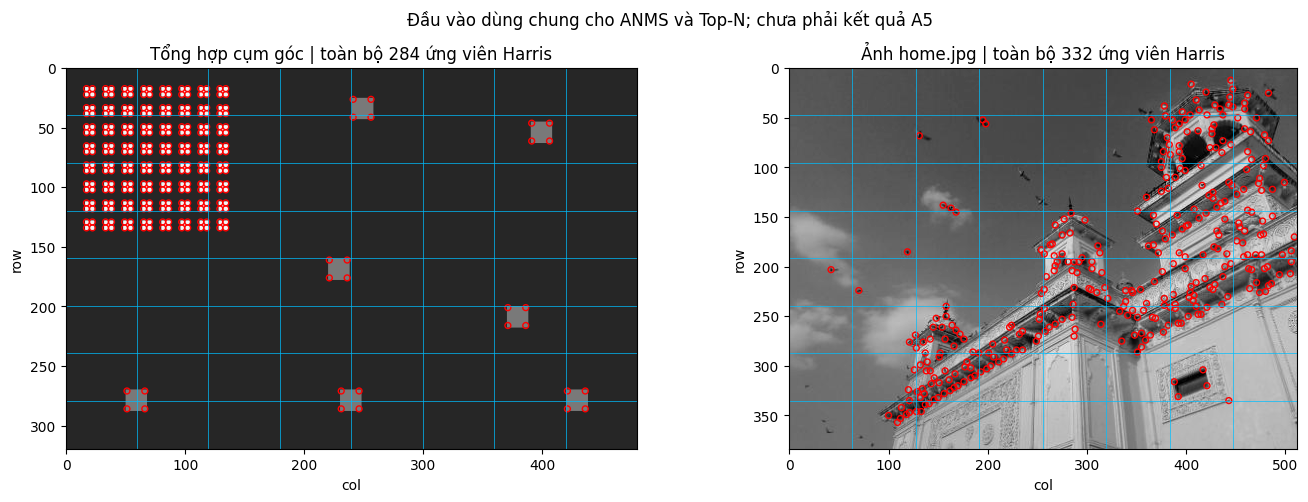

In [10]:
# Ảnh tổng hợp có một cụm góc tương phản mạnh và các cấu trúc yếu hơn phân tán.
# Đây là dữ liệu thí nghiệm, không phải kết quả phát hiện góc.
synthetic = np.full((320,480), 0.15, dtype=float)
for row in range(16,144,16):
    for col in range(16,144,16):
        synthetic[row:row+8, col:col+8] = 0.95
for row,col in [(25,240),(45,390),(160,220),(200,370),(270,50),(270,230),(270,420)]:
    synthetic[row:row+18,col:col+18] = 0.48
len_images = {'Tổng hợp cụm góc': synthetic}
real_path = IMAGES_DIR / 'home.jpg'
if real_path.is_file():
    len_images['Ảnh home.jpg'] = len_read_gray(real_path)
else:
    print('CHƯA CÓ ảnh thật:', real_path, '| cần bổ sung trước khi kết luận trên ảnh thật.')

fig, axes = plt.subplots(1, len(len_images), figsize=(6*len(len_images),4), squeeze=False)
for ax, (name, img) in zip(axes[0], len_images.items()):
    ax.imshow(img,cmap='gray',vmin=0,vmax=1); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

len_candidates = {}
if callable(globals().get('harris_classic')) and HARRIS_SOURCE_COMMIT.strip():
    for name,img in len_images.items():
        points = np.asarray(harris_classic(img.copy(), **LEN_HARRIS), dtype=float)
        if points.ndim != 2 or points.shape[1] != 3 or not np.isfinite(points).all():
            raise AssertionError(f'{name}: Harris phải trả mảng hữu hạn (M,3).')
        if len(points):
            assert np.all(points[:,2] > 0), 'Cấu hình này cần các ứng viên góc có response dương.'
            assert np.all(np.diff(points[:,2]) <= 0), 'Harris phải sắp giảm dần theo response.'
            assert np.all((points[:,0]>=0)&(points[:,0]<img.shape[0]))
            assert np.all((points[:,1]>=0)&(points[:,1]<img.shape[1]))
        len_candidates[name] = points.copy()
        print(name, '| số ứng viên:', len(points))
else:
    print('CHƯA SINH ứng viên: cần harris_classic và mã commit/PR Harris đã duyệt.')

# Hiển thị toàn bộ ứng viên thực sự trả về từ Harris một tỉ lệ.
# Đây chưa phải tập điểm đã chọn bằng ANMS hoặc Top-N.
if len_candidates:
    fig, axes = plt.subplots(1, len(len_candidates), figsize=(7*len(len_candidates), 5), squeeze=False)
    for ax, (name, points) in zip(axes[0], len_candidates.items()):
        len_plot_points(ax, len_images[name], points, LEN_GRID,
                        f'{name} | toàn bộ {len(points)} ứng viên Harris')
    fig.suptitle('Đầu vào dùng chung cho ANMS và Top-N; chưa phải kết quả A5')
    plt.tight_layout(); plt.show()


### 2.4 – So sánh A5: cùng ứng viên, cùng N và cùng lưới

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Dựng kiểm chứng A5 và đo hai đầu ra thật; không tự điền kết quả khi chưa có thuật toán.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482  
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

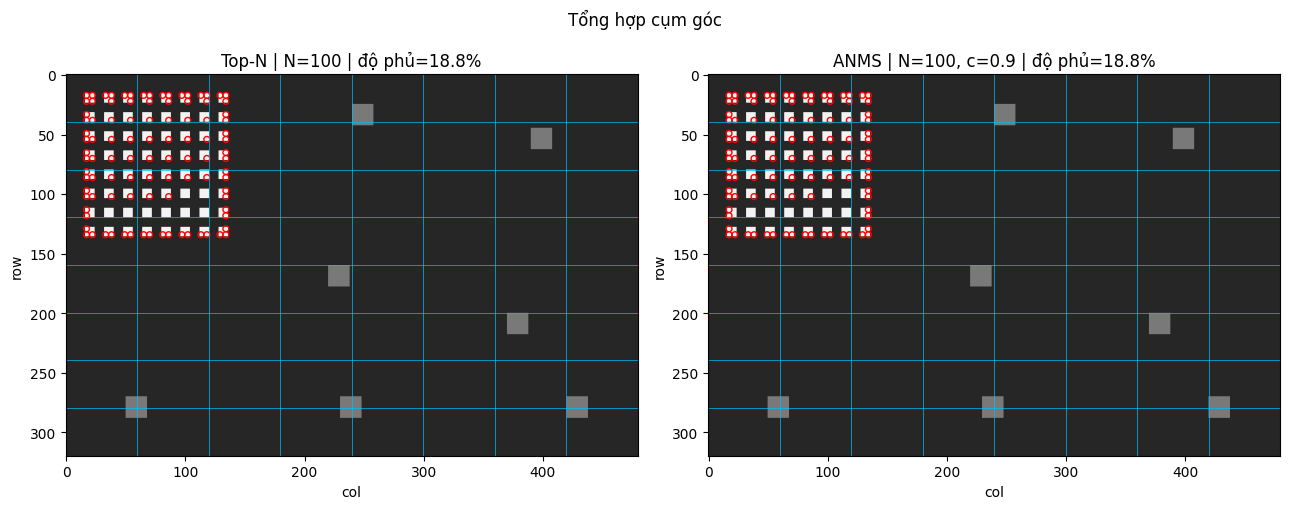

Tổng hợp cụm góc: M=284, N=100, grid=(8, 8), Top-N=0.1875, ANMS=0.1875, chênh lệch=+0.00 điểm phần trăm.


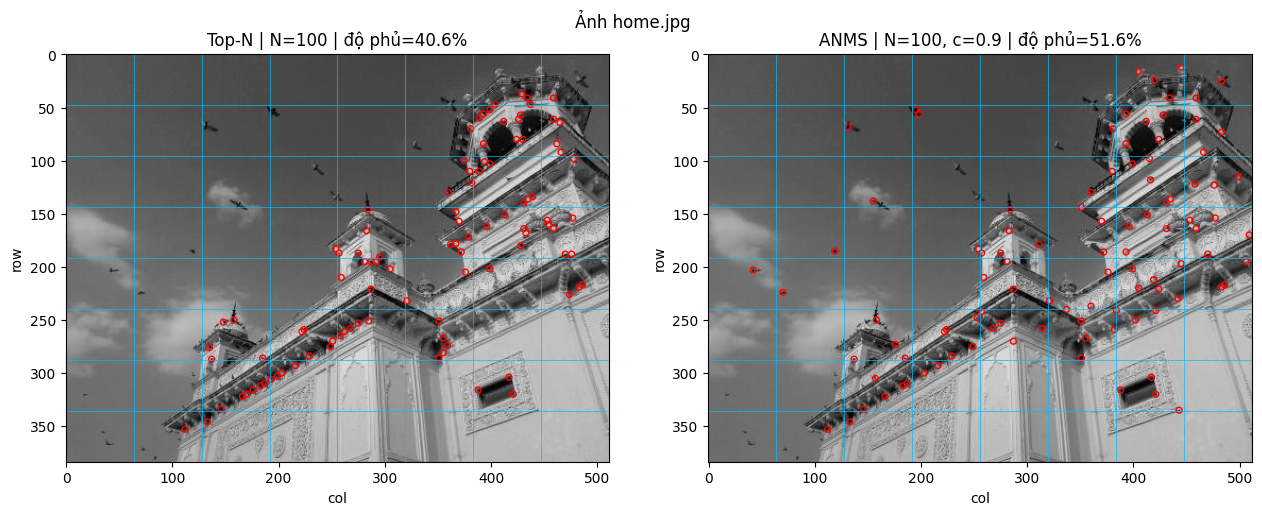

Ảnh home.jpg: M=332, N=100, grid=(8, 8), Top-N=0.4062, ANMS=0.5156, chênh lệch=+10.94 điểm phần trăm.
Số ảnh đã đo A5: 2
Độ phủ lớn hơn không đồng nghĩa định vị góc chính xác hơn.


In [11]:
len_a5_rows = []
missing = len_missing(['anms','top_n','grid_occupancy'])
if missing or not len_candidates:
    print('CHƯA CHẠY A5. Hàm thiếu:', missing, '| số tập ứng viên:', len(len_candidates))
else:
    for name, points in len_candidates.items():
        if len(points) < 2:
            print(name, ': quá ít ứng viên để so sánh.'); continue
        n = min(LEN_N, len(points))
        img = len_images[name]
        top = len_check_selected(top_n(points.copy(), n), points, n)
        kept = len_check_selected(anms(points.copy(), n, c_robust=LEN_C), points, n)
        cov_top = len_measure_coverage(top, img.shape, LEN_GRID)
        cov_anms = len_measure_coverage(kept, img.shape, LEN_GRID)
        len_a5_rows.append(dict(image=name, candidates=len(points), n=n,
                               c_robust=LEN_C, top=cov_top, anms=cov_anms))
        fig, axes = plt.subplots(1,2,figsize=(13,5))
        len_plot_points(axes[0],img,top,LEN_GRID,f'Top-N | N={n} | độ phủ={cov_top:.1%}')
        len_plot_points(axes[1],img,kept,LEN_GRID,f'ANMS | N={n}, c={LEN_C} | độ phủ={cov_anms:.1%}')
        fig.suptitle(name); plt.tight_layout(); plt.show()
        print(f'{name}: M={len(points)}, N={n}, grid={LEN_GRID}, '
              f'Top-N={cov_top:.4f}, ANMS={cov_anms:.4f}, '
              f'chênh lệch={(cov_anms-cov_top)*100:+.2f} điểm phần trăm.')

print('Số ảnh đã đo A5:', len(len_a5_rows))
print('Độ phủ lớn hơn không đồng nghĩa định vị góc chính xác hơn.')

### Nhận xét và bàn giao A5 trước 14/11

Khi đã chạy, ghi rõ ảnh, M, N thực tế, lưới, hai độ phủ và chênh lệch. Nếu ANMS bằng hoặc kém Top-N, báo nguyên kết quả và kiểm tra phân bố response, các bán kính vô cùng, hòa thứ hạng, kích thước lưới. Không tăng N của ANMS để làm chỉ số đẹp hơn.

**Trạng thái hiện tại:** chưa có số đo thuật toán trong bản chuẩn bị; output “CHƯA CHẠY” không phải kết quả kiểm chứng đạt. Sau khi Nam/Hiệp duyệt, điền dẫn chiếu thật vào `A5_APPROVAL_REF` và Restart & Run All.

## 3. Vòng 3 – Thí nghiệm A2, hạn 16/11/2026

Thiết kế hai trục quét để thấy được xu hướng, không chỉ vài ảnh rời:
- Quét `c_robust`: 0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00; giữ cùng N, ảnh, ứng viên Harris và lưới. Top-N chỉ là đường đối chứng không phụ thuộc c.
- Quét N: 25, 50, 75, 100, 150, 200; giữ c=0.9 và toàn bộ điều kiện còn lại. Loại giá trị N vượt số ứng viên và công bố rõ các giá trị không chạy.

Ảnh tổng hợp kiểm tra mức tập trung của các điểm mạnh; ảnh thật kiểm tra khả năng áp dụng. Không suy rộng kết quả hai ảnh thành bảo đảm cho mọi ảnh. Với lưới 8×8, độ phủ có thể bão hòa khi các ô đã được lấp đầy; thêm điểm lúc đó không nhất thiết tăng chỉ số.

### 3.1 – Quét c_robust và vẽ đường cong độ phủ

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Dựng vòng lặp quét c_robust, giữ cùng dữ liệu và số điểm, chỉ thực thi sau phê duyệt A5.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482  
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

In [12]:
len_sweep_c = []
len_stage3_ready = (bool(A5_APPROVAL_REF.strip()) and bool(len_a5_rows)
                    and not len_missing(['anms','top_n','grid_occupancy']))
if not len_stage3_ready:
    print('CHƯA CHẠY Vòng 3: cần đủ hàm, số đo A5 và dẫn chiếu phê duyệt A5.')
else:
    for name,points in len_candidates.items():
        if len(points)<2: continue
        n=min(LEN_N,len(points)); img=len_images[name]
        top=len_check_selected(top_n(points.copy(),n),points,n)
        baseline=len_measure_coverage(top,img.shape,LEN_GRID)
        for c in [0.50,0.60,0.70,0.80,0.90,0.95,1.00]:
            kept=len_check_selected(anms(points.copy(),n,c_robust=c),points,n)
            coverage=len_measure_coverage(kept,img.shape,LEN_GRID)
            len_sweep_c.append(dict(image=name,n=n,c=c,top=baseline,anms=coverage))
        rows=[r for r in len_sweep_c if r['image']==name]
        plt.figure(figsize=(7,4))
        plt.plot([r['c'] for r in rows],[r['anms'] for r in rows],'o-',label='ANMS')
        plt.axhline(baseline,color='orange',linestyle='--',label='Top-N (cố định)')
        plt.xlabel('c_robust');plt.ylabel('Độ phủ');plt.ylim(-0.03,1.03)
        plt.title(f'{name} | N={n} | lưới={LEN_GRID}')
        plt.legend();plt.grid(alpha=0.3);plt.tight_layout();plt.show()
        for r in rows:print(r)

CHƯA CHẠY Vòng 3: cần đủ hàm, số đo A5 và dẫn chiếu phê duyệt A5.


### 3.2 – Quét số điểm N với cùng c_robust

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Quét N hợp lệ trên cùng ứng viên và vẽ hai đường cong; ghi rõ các cấu hình không chạy.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

In [13]:
len_sweep_n=[]
if not len_stage3_ready:
    print('CHƯA CHẠY quét N: điều kiện Vòng 3 chưa đủ.')
else:
    for name,points in len_candidates.items():
        values=[n for n in [25,50,75,100,150,200] if n<=len(points)]
        skipped=[n for n in [25,50,75,100,150,200] if n>len(points)]
        print(name,'| N hợp lệ:',values,'| bỏ qua vì vượt M:',skipped)
        if len(values)<2:
            print('Chưa đủ ít nhất hai N để vẽ xu hướng; cần chọn ảnh/cấu hình ứng viên phù hợp.');continue
        img=len_images[name]
        for n in values:
            top=len_check_selected(top_n(points.copy(),n),points,n)
            kept=len_check_selected(anms(points.copy(),n,c_robust=LEN_C),points,n)
            len_sweep_n.append(dict(image=name,n=n,c=LEN_C,
                top=len_measure_coverage(top,img.shape,LEN_GRID),
                anms=len_measure_coverage(kept,img.shape,LEN_GRID)))
        rows=[r for r in len_sweep_n if r['image']==name]
        plt.figure(figsize=(7,4))
        plt.plot([r['n'] for r in rows],[r['top'] for r in rows],'s--',label='Top-N')
        plt.plot([r['n'] for r in rows],[r['anms'] for r in rows],'o-',label='ANMS')
        plt.xlabel('Số điểm N');plt.ylabel('Độ phủ');plt.ylim(-0.03,1.03)
        plt.title(f'{name} | c={LEN_C} | lưới={LEN_GRID}')
        plt.legend();plt.grid(alpha=0.3);plt.tight_layout();plt.show()
        for r in rows:print(r)

CHƯA CHẠY quét N: điều kiện Vòng 3 chưa đủ.


### 3.3 – Nhận xét tự động từ số liệu thật

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Tổng hợp đúng các số đo đã chạy, báo cả cấu hình không cải thiện và tránh kết luận dựng sẵn.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482  
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

In [14]:
if not len_sweep_c and not len_sweep_n:
    print('CHƯA CÓ số liệu Vòng 3. Không kết luận ANMS tốt hơn khi chưa đo.')
for source,title in [(len_sweep_c,'quét c'),(len_sweep_n,'quét N')]:
    for name in sorted({r['image'] for r in source}):
        rows=[r for r in source if r['image']==name]
        diffs=np.array([r['anms']-r['top'] for r in rows])
        better=int(np.sum(diffs>1e-12));equal=int(np.sum(np.abs(diffs)<=1e-12));worse=int(np.sum(diffs < -1e-12))
        print(f'{name}, {title}: ANMS hơn/bằng/kém Top-N = {better}/{equal}/{worse} trên {len(rows)} cấu hình.')
        print(f'Chênh lệch độ phủ: {100*diffs.min():+.2f} đến {100*diffs.max():+.2f} điểm phần trăm.')
print('Khi viết giải thích: nối khác biệt độ phủ với lựa chọn theo r_i; phân biệt độ phủ với độ chính xác định vị.')

CHƯA CÓ số liệu Vòng 3. Không kết luận ANMS tốt hơn khi chưa đo.
Khi viết giải thích: nối khác biệt độ phủ với lựa chọn theo r_i; phân biệt độ phủ với độ chính xác định vị.


### Khung viết nhận xét bằng lời sau khi chạy

1. **Đại lượng nào thay đổi?** Ghi độ phủ Top-N/ANMS và chênh lệch tại các cấu hình cụ thể từ output.
2. **Thay đổi ở bước nào?** Cả hai nhận cùng điểm Harris; khác biệt phát sinh ở bước chọn điểm theo response hoặc theo bán kính ANMS, không phải do ảnh đầu vào hay Harris thay đổi.
3. **Vì sao?** Đối chiếu cụm góc mạnh và góc yếu tách biệt; giải thích điều kiện đủ mạnh `f_i < c_robust f_j`, các điểm có r=∞ và quy tắc hòa.
4. **Giới hạn:** một chỉ số độ phủ không đo sai số định vị; ảnh/lưới/N có thể khiến chỉ số bão hòa, hai phương pháp bằng nhau hoặc ANMS kém hơn. Không khẳng định độ phủ tăng đơn điệu theo c.

## 4. Vòng 4 – Hoàn thiện A2 và duyệt chéo SRG, hạn 17/11/2026

### 4.1 – Checklist A2 của Lên

- [ ] Cài đặt tự viết, đúng điều kiện ức chế; không thay ANMS bằng NMS cửa sổ cố định.
- [ ] Cùng Harris một tỉ lệ và cùng tập ứng viên trong mọi cặp so sánh.
- [ ] Top-N và ANMS cùng N và cùng lưới; tọa độ vẽ x=col, y=row.
- [ ] `grid_occupancy` có nguồn và đúng giao diện đã thống nhất.
- [ ] A5 có output, ảnh lưới và số đo; Nam/Hiệp đã duyệt.
- [ ] Quét tham số có đường cong, nhận xét khớp số liệu, có giải thích theo r_i.
- [ ] Gấm rà lại số đo ngày 15–16/11; Hiệp duyệt phần A2 trước gộp.
- [ ] Restart & Run All sau khi có đủ cài đặt, không còn thông báo CHƯA CHẠY; lưu output thật.

### 4.2 – Vai trò duyệt chéo SRG của Hiệp (đừng bỏ sót)

| Mốc | Lên cần kiểm tra | Bằng chứng cần nhận | Trạng thái từ main lúc đọc |
|---|---|---|---|
| 13/11 – vòng 1 Hiệp | Giao diện srg và srg_step_frames, các chế độ stale/tie, liên thông 4/8 | Commit/PR, cấu hình gọi hàm, output | Chưa có cài đặt |
| 14/11 – kiểm chứng B5 | Ảnh phẳng + 2 seeds; hình dạng vùng theo tie; lazy/frozen phủ hết ảnh; 8 snapshot | Ảnh nhãn, số nhãn/pixel chưa gán, 8 ảnh tiến trình, seed ngẫu nhiên | Chưa có output |
| 16/11 – thí nghiệm SRG | Ảnh chuyển màu cho lazy/frozen; ít nhất 1 ảnh thay tie làm đổi kết quả; có thời gian và số đo | Ảnh gốc, seeds/ID cố định, tham số, bảng sai khác và thời gian | Chưa có output |
| **17/11 – duyệt chéo cuối** | Đối chiếu bản gộp, ghi lỗi cho Hiệp tự sửa, Lên + Sen xác nhận | Danh sách lỗi, cách tái hiện, commit sửa và kết quả chạy lại | Chưa xác nhận |

**Cách duyệt có thể tái hiện:** dùng đúng một ảnh và cùng seeds/ID cho mỗi cặp; ghi connectivity, stale, tie và random seed. Nếu đổi thứ tự seeds, giữ/căn chỉnh ý nghĩa ID trước khi đếm pixel khác nhau. Kiểm tra labels cùng kích thước ảnh, mọi pixel có nhãn và số vùng khớp số seeds hợp lệ. Với ảnh phẳng, không ép kết quả phải có một hình dạng định trước: quan sát hình dạng thực tế và nối với cách phá hòa. Khi kiểm tra snapshot, xác nhận là bản sao ở các mốc, không phải nhiều tham chiếu cùng một ảnh cuối.

**Lỗi thuật toán SRG:** Lên ghi điều kiện tái hiện và bằng chứng, Hiệp tự sửa theo phân công; không sửa hộ rồi nhận đã duyệt. Chưa có mã SRG thì trạng thái đúng là **chờ bàn giao**, không phải “đạt”.

### 4.3 – Bàn giao và đóng gói

**Vai trò bổ sung với phần B của Sen:** ngày **14/11**, Lên kiểm cách đếm pixel khác nhau trong B1–B4, nhất là căn chỉnh ID nhãn trước khi so sánh và dùng cùng ảnh/seeds; ngày **17/11**, Lên xác nhận phần B ghép của Sen + Hiệp đủ 5 kiểm chứng B và 3 yêu cầu thí nghiệm cặp B, có dữ liệu chạy lại. Đây là nhiệm vụ duyệt trong hàng 13 và 23 của sheet, không phải một phần cài đặt mới của Lên. Hiện cả hai việc vẫn chờ bằng chứng bàn giao.

- Nhánh cá nhân `bt2-len`, chỉ sửa notebook phần mình và ảnh thật sự cần dùng. Quy trình: lưu notebook → commit → push → PR → người duyệt kiểm tra → Hiệp merge.
- Trong repo, dùng `images/` tại gốc. Khi Hiệp đóng gói theo đề, chép ảnh cần dùng sang `anh/`, sửa đường dẫn bản nộp và chạy lại; không cần đưa toàn bộ ảnh bài cũ vào bài 2.
- 18/11 là mốc Hiệp gộp xong; hạn của phần Lên vẫn là **17/11**. Hạn nộp chung **20/11/2026**.
- Tên file nộp LMS cần Hiệp xác nhận vì đề được mô tả có mẫu `bt1_<Nhom>.ipynb`, còn tên làm việc là `bt2_nhom.ipynb`.

### 4.4 – Báo cáo trạng thái thực tế, không tự đánh dấu hoàn thành

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Tổng hợp tiến độ từ trạng thái thật của notebook, không cập nhật hay tự duyệt tiến độ trong Google Sheet.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482  
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

**Cập nhật ngày 12/11/2026 – ChatGPT / Codex hỗ trợ:** Tách rõ phần Harris đã nhận và số ứng viên đã chạy với các nhiệm vụ ANMS/A5 còn thiếu.

Prompt nguyên văn cho lần cập nhật:

```text
[https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec](https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec)
```

In [15]:
len_status = {
    'Bàn giao Harris từ Gấm': f'Đã nhận 5 hàm, {len(len_harris_handoff)}/3 kiểm tra tích hợp đạt',
    'Ứng viên Harris': '; '.join(f'{name}: {len(p)} điểm' for name,p in len_candidates.items()),
    '12/11 – Hàm cá nhân': 'Đã có tên hàm; cần người duyệt kiểm tra' if not len_missing(['anms','top_n','grid_occupancy']) else 'Chờ cài đặt cá nhân / hàm của đề',
    '14/11 – A5': f'Đã đo {len(len_a5_rows)} ảnh' if len_a5_rows else 'Chưa có số đo',
    '16/11 – Quét tham số': f'{len(len_sweep_c)} cấu hình c; {len(len_sweep_n)} cấu hình N' if len_sweep_c or len_sweep_n else 'Chưa thực hiện',
    '17/11 – Duyệt SRG': 'Chờ bàn giao và đánh giá; không tự xác nhận',
}
for name,value in len_status.items():
    print(name, '|', value)
print('Số nhóm kiểm tra điểm giả đã chạy:', len(len_unit_results), '/ 5')
print('Nguồn Harris:', HARRIS_SOURCE_COMMIT or 'chưa ghi nhận')
print('Dẫn chiếu duyệt A5:', A5_APPROVAL_REF or 'chưa có')
print('Bản chạy không lỗi nhưng còn CHƯA CHẠY/Chờ cài đặt không phải bản nộp đã hoàn thành.')

Bàn giao Harris từ Gấm | Đã nhận 5 hàm, 3/3 kiểm tra tích hợp đạt
Ứng viên Harris | Tổng hợp cụm góc: 284 điểm; Ảnh home.jpg: 332 điểm
12/11 – Hàm cá nhân | Đã có tên hàm; cần người duyệt kiểm tra
14/11 – A5 | Đã đo 2 ảnh
16/11 – Quét tham số | Chưa thực hiện
17/11 – Duyệt SRG | Chờ bàn giao và đánh giá; không tự xác nhận
Số nhóm kiểm tra điểm giả đã chạy: 5 / 5
Nguồn Harris: 86c128c6933fcf07777f2ee3a6d6fa327128960b
Dẫn chiếu duyệt A5: chưa có
Bản chạy không lỗi nhưng còn CHƯA CHẠY/Chờ cài đặt không phải bản nộp đã hoàn thành.
